In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

import opendata_bcn as bcn

income = bcn.download_income(2023)      # disposable income per person (EUR), 2023
pop = bcn.download_population(2024)     # population on 1 January 2024
sections = bcn.download_sections()      # census section polygons
shelters = bcn.download_shelters()      # climate shelters (points)

sec = (sections.merge(income[["section_id", "income_eur"]], on="section_id", validate="one_to_one")
               .merge(pop, on="section_id", validate="one_to_one"))
print(len(sections), len(sec), int(sec["population"].sum()), sec.crs)
print(len(shelters), shelters.crs, int(shelters.geometry.is_empty.sum()), "empty geometries")
print("area of the sections (km2):", round(sec.area.sum() / 1e6, 1))
print("income range (EUR):", sec["income_eur"].min(), sec["income_eur"].max())


1068 1068 1702814 EPSG:25831
564 EPSG:25831 0 empty geometries
area of the sections (km2): 101.7
income range (EUR): 11097 54089


In [2]:
def weighted_decile(income, weight):
    # decile of each section, with about 10 % of the population in each decile
    order = np.argsort(income.to_numpy())
    w = weight.to_numpy()[order]
    mid = (np.cumsum(w) - w / 2) / w.sum()
    dec = np.empty(len(income), dtype=int)
    dec[order] = np.minimum((mid * 10).astype(int) + 1, 10)
    return dec


sec["decile"] = weighted_decile(sec["income_eur"], sec["population"])
print(sec.groupby("decile").agg(sections=("section_id", "count"),
                                 population=("population", "sum"),
                                 income_min=("income_eur", "min"),
                                 income_max=("income_eur", "max")).to_string())


        sections  population  income_min  income_max
decile                                              
1             87      170209       11097       17508
2            106      170751       17538       20082
3            111      170136       20106       22015
4            105      169987       22046       23425
5            105      171007       23436       24609
6            113      169856       24615       26176
7            108      169315       26178       27675
8            111      170566       27702       30325
9            111      170688       30355       36005
10           111      170299       36227       54089


In [3]:
# Coverage: share of each section's area within a distance of the nearest shelter
# (straight line in a metric projection; population assumed uniform inside a section)
for radius in (400, 800):
    zone = shelters.buffer(radius).union_all()
    share = sec.geometry.intersection(zone).area / sec.geometry.area
    sec[f"pop_{radius}"] = sec["population"] * share

# Check with a second, rougher measure: distance from one point of each section
points = sec.geometry.representative_point()
sec["dist_m"] = points.apply(lambda p: shelters.distance(p).min())

# shelters inside each section
inside = gpd.sjoin(shelters, sec[["section_id", "decile", "geometry"]], predicate="within")
sec["n_shelters"] = sec["section_id"].map(inside.groupby("section_id").size()).fillna(0)

by = sec.groupby("decile").agg(
    population=("population", "sum"), pop_400=("pop_400", "sum"), pop_800=("pop_800", "sum"),
    shelters=("n_shelters", "sum"), area_km2=("geometry", lambda g: g.area.sum() / 1e6),
    median_dist_m=("dist_m", "median"), median_income=("income_eur", "median"))
by["pct_400"] = 100 * by["pop_400"] / by["population"]
by["pct_800"] = 100 * by["pop_800"] / by["population"]
by["shelters_per_km2"] = by["shelters"] / by["area_km2"]
print(by[["median_income", "pct_400", "pct_800", "shelters", "shelters_per_km2",
          "median_dist_m"]].round(1).to_string())
print("city: within 400 m", round(100 * sec["pop_400"].sum() / sec["population"].sum(), 1),
      "% | within 800 m", round(100 * sec["pop_800"].sum() / sec["population"].sum(), 1), "%")
print("shelters counted in sections:", int(sec["n_shelters"].sum()), "of", len(shelters))
print("Spearman income vs distance:", round(sec["income_eur"].corr(sec["dist_m"], method="spearman"), 2))


        median_income  pct_400  pct_800  shelters  shelters_per_km2  median_dist_m
decile                                                                            
1             15721.0     97.1    100.0      58.0               7.4          152.9
2             19064.0     97.1     99.0      56.0               2.6          176.8
3             21067.0     96.1     99.0      52.0               4.3          175.9
4             22864.0     99.7    100.0      47.0              10.1          151.3
5             24068.0     97.7     99.8      58.0               9.1          159.4
6             25538.0     98.2     98.9      77.0               5.5          145.4
7             27000.5     97.7    100.0      48.0               8.7          157.0
8             28707.0     98.2    100.0      58.0               9.4          152.9
9             33067.0     95.8    100.0      53.0               8.5          159.2
10            41802.0     88.3     98.6      56.0               3.2          214.7
city

Spearman income vs distance: 0.07


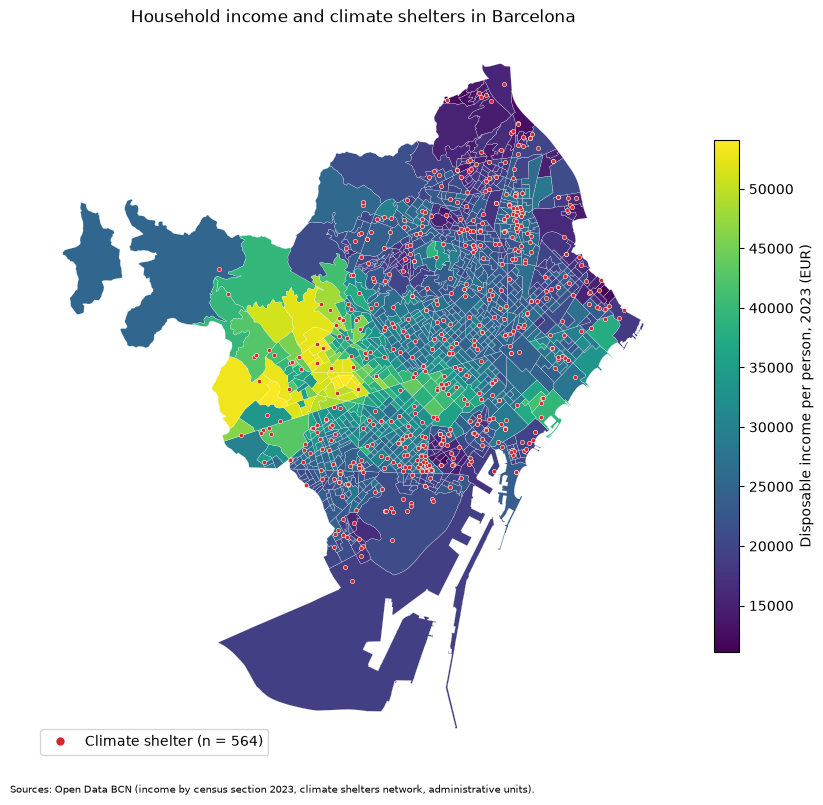

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 8))
sec.plot(column="income_eur", cmap="viridis", ax=ax, edgecolor="white", linewidth=0.15,
         legend=True,
         legend_kwds={"label": "Disposable income per person, 2023 (EUR)", "shrink": 0.7})
shelters.plot(ax=ax, color="tab:red", markersize=9, edgecolor="white", linewidth=0.4)
ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:red",
                          markeredgecolor="white", markersize=7,
                          label=f"Climate shelter (n = {len(shelters)})")],
          loc="lower left", frameon=True)
ax.set_axis_off()
ax.set_title("Household income and climate shelters in Barcelona")
fig.text(0.01, 0.01,
         "Sources: Open Data BCN (income by census section 2023, climate shelters network, "
         "administrative units).", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))

out = Path("..") / "figures"
out.mkdir(exist_ok=True)
fig.savefig(out / "idea2_income_shelters_map.png", dpi=200)
fig.savefig(out / "idea2_income_shelters_map.svg")


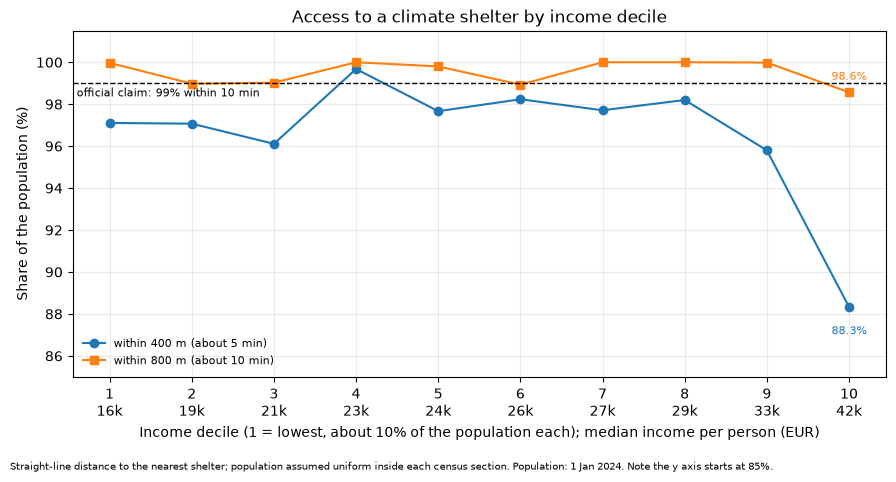

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(1, 11)
ax.plot(x, by["pct_400"], marker="o", color="tab:blue", label="within 400 m (about 5 min)")
ax.plot(x, by["pct_800"], marker="s", color="tab:orange", label="within 800 m (about 10 min)")
ax.axhline(99, color="black", ls="--", lw=1)
ax.text(0.6, 98.8, "official claim: 99% within 10 min", ha="left", va="top", fontsize=8)
for col, color, dy in (("pct_400", "tab:blue", -1.3), ("pct_800", "tab:orange", 0.6)):
    ax.text(10, by.loc[10, col] + dy, f"{by.loc[10, col]:.1f}%", color=color, ha="center",
            fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{d}\n{by.loc[d, 'median_income'] / 1000:.0f}k" for d in x])
ax.set_xlabel("Income decile (1 = lowest, about 10% of the population each); "
              "median income per person (EUR)")
ax.set_ylabel("Share of the population (%)")
ax.set_ylim(85, 101.5)
ax.set_title("Access to a climate shelter by income decile")
ax.legend(loc="lower left", fontsize=8, frameon=False)
ax.grid(alpha=0.25)
fig.text(0.01, 0.01,
         "Straight-line distance to the nearest shelter; population assumed uniform inside each "
         "census section. Population: 1 Jan 2024. Note the y axis starts at 85%.",
         fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(out / "idea2_accessibility_by_income.png", dpi=200)
fig.savefig(out / "idea2_accessibility_by_income.svg")
